# M16 · 02 — Ablations at ~110M (A1)

Decision: `docs/decisions/0025-own-llm-m16.md` §3. Configs: `configs/make_ablations.py` → `configs/ablations/*.yaml`.

Each run trains on the same 1B-token prefix of the 70/30 mix, with the same seed, and differs from `a1-baseline` in exactly one thing.

| run | change |
|---|---|
| a1-baseline | §2 recipe: d768/L12, GQA 12/4, SwiGLU, RoPE θ=1e5, AdamW lr 1e-3, WSD |
| a1b-lr2e-3 | lr 2e-3 (sensitivity: a win must not just be a better LR) |
| a2-muon | Muon on hidden matrices + AdamW on embedding/norms |
| a3-qknorm | per-head q/k RMSNorm |
| a4-relu2 | ReLU² MLP, same parameter count (no llama.cpp graph) |
| a5-deep | d576/L21 (~74M non-embedding) |
| a5b-wide | d1024/L7 (~76M non-embedding) |
| a6-cosine | cosine LR schedule |

**Adoption rule (§3):** a change is adopted if it improves combined bits per byte by ≥ 0.01 at ≤ 10 % throughput cost, or if it improves bpb at no cost. Changes llama.cpp can't run need a big win and the owner's agreement (§2).

Launch (one queue, pausable with `llm-pause`):
```
python -m llm.train start configs/ablations/a1-baseline.yaml configs/ablations/a1b-lr2e-3.yaml ...
```

In [1]:
import json
from pathlib import Path
from llm.train import runs_root, read_status

ORDER = ['a1-baseline', 'a1b-lr2e-3', 'a2-muon', 'a3-qknorm', 'a4-relu2', 'a5-deep', 'a5b-wide', 'a6-cosine']
runs = {}
for name in ORDER:
    d = runs_root() / f'ablation-{name}'
    if not (d / 'metrics.jsonl').exists():
        continue
    recs = [json.loads(l) for l in (d / 'metrics.jsonl').read_text().splitlines()]
    runs[name] = {'evals': [r for r in recs if r['event'] == 'eval'],
                  'train': [r for r in recs if r['event'] == 'train'],
                  'state': read_status(d).get('state')}
for n, r in runs.items():
    print(f"{n:12s} {r['state']:8s} evals={len(r['evals'])}")

a1-baseline  done     evals=11
a1b-lr2e-3   done     evals=11
a2-muon      done     evals=11
a3-qknorm    done     evals=12
a4-relu2     done     evals=11
a5-deep      done     evals=11
a5b-wide     done     evals=11
a6-cosine    done     evals=11


In [2]:
def final(r):
    ev = r['evals'][-1] if r['evals'] else {}
    tps = [t['tok_s'] for t in r['train'][len(r['train']) // 5:]]  # skip warm-up/compile
    return ev, (sorted(tps)[len(tps) // 2] if tps else float('nan'))

base_ev, base_tps = final(runs['a1-baseline']) if 'a1-baseline' in runs else ({}, float('nan'))
print(f"{'run':12s} {'bpb':>7s} {'Δ vs base':>9s} {'es':>7s} {'en':>7s} {'tok/s':>8s} {'Δ speed':>8s}  verdict")
for n, r in runs.items():
    ev, tps = final(r)
    if not ev:
        continue
    d = ev['val_bpb'] - base_ev.get('val_bpb', float('nan'))
    ds = tps / base_tps - 1
    verdict = '' if n == 'a1-baseline' else ('ADOPT' if (d <= -0.01 and ds >= -0.10) or (d < 0 and ds >= 0) else 'no')
    print(f"{n:12s} {ev['val_bpb']:7.4f} {d:+9.4f} {ev.get('val_bpb_es', float('nan')):7.4f} "
          f"{ev.get('val_bpb_en', float('nan')):7.4f} {tps:8,.0f} {ds:+8.1%}  {verdict}")

run              bpb Δ vs base      es      en    tok/s  Δ speed  verdict
a1-baseline   1.0743   +0.0000  0.9886  1.1601   68,775    +0.0%  
a1b-lr2e-3    1.0579   -0.0164  0.9738  1.1420   68,841    +0.1%  ADOPT
a2-muon       1.0503   -0.0241  0.9661  1.1345   67,241    -2.2%  ADOPT
a3-qknorm     1.0652   -0.0091  0.9809  1.1496   67,606    -1.7%  no
a4-relu2      1.0753   +0.0010  0.9901  1.1606   66,986    -2.6%  no
a5-deep       1.0770   +0.0026  0.9912  1.1627   61,019   -11.3%  no
a5b-wide      1.0705   -0.0038  0.9854  1.1556   67,874    -1.3%  no
a6-cosine     1.1049   +0.0305  1.0161  1.1937   68,894    +0.2%  no


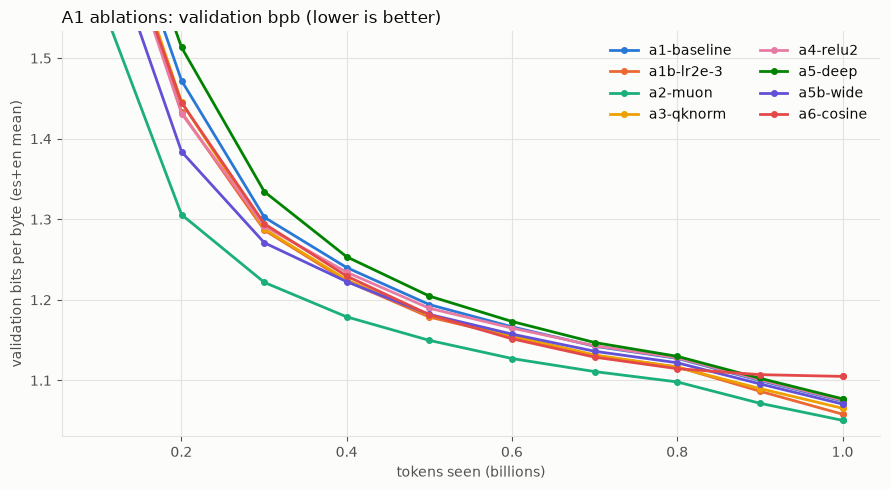

In [3]:
# Validation bits per byte vs tokens seen. One axis; categorical palette in fixed slot order
# (dataviz reference palette, light mode); legend + the table above as the table view.
import matplotlib.pyplot as plt
SLOTS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
fig, ax = plt.subplots(figsize=(9, 5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for i, n in enumerate(ORDER):
    if n not in runs or not runs[n]['evals']:
        continue
    ev = runs[n]['evals']
    ax.plot([e['tokens'] / 1e9 for e in ev], [e['val_bpb'] for e in ev], color=SLOTS[i], lw=2,
            marker='o', ms=4, label=n)
ax.set_xlabel('tokens seen (billions)', color=MUTED)
ax.set_ylabel('validation bits per byte (es+en mean)', color=MUTED)
ax.set_title('A1 ablations: validation bpb (lower is better)', color=INK, loc='left')
ax.grid(True, color=GRID, lw=0.8)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, labelcolor=INK, ncol=2)
if runs:
    lo = min(e['val_bpb'] for r in runs.values() for e in r['evals'][1:] or r['evals'])
    hi = max(e['val_bpb'] for r in runs.values() for e in r['evals'][1:] or r['evals'])
    ax.set_ylim(lo - 0.02, hi + 0.02)
plt.tight_layout()
plt.show()

## Conclusions

Measured on 2026-11-17 02:17, after all 8 runs finished (1B tokens each, same prefix and seed). bpb is the es/en mean of the last eval; tok/s is the median after the first 20 % of steps.

| run | bpb | Δ vs baseline | Δ speed | rule |
|---|---|---|---|---|
| a1-baseline | 1.0743 | — | — | — |
| a1b-lr2e-3 | 1.0579 | −0.0164 | +0.1 % | **adopt** |
| a2-muon | 1.0503 | −0.0241 | −2.2 % | passes vs baseline, **fails vs a1b** (see below) |
| a3-qknorm | 1.0652 | −0.0091 | −1.7 % | no (< 0.01 with a cost) |
| a4-relu2 | 1.0753 | +0.0010 | −2.6 % | no (worse; no llama.cpp graph anyway) |
| a5-deep | 1.0770 | +0.0026 | −11.3 % | no |
| a5b-wide | 1.0705 | −0.0038 | −1.3 % | no (< 0.01 with a cost) |
| a6-cosine | 1.1049 | +0.0305 | +0.2 % | no (WSD stays) |

- **LR check (§3).** The baseline's lr 1e-3 is too low: lr 2e-3 alone gives −0.0164 at no cost. Every other candidate was run at lr 1e-3, so a win has to beat a1b and not only the baseline.
- **Muon** (hidden matrices at muon_lr 0.02, AdamW lr 1e-3 for embeddings and norms) beats a1b by only **0.0076** bpb, at 2.3 % lower throughput. That is below the 0.01 threshold, so it is **not adopted**. It is the closest call of A1, and Muon combined with a higher AdamW LR was not measured.
- **QK-norm** (−0.0091) and **wide** (−0.0038) fall short of 0.01. ReLU² does not win, so nothing has to go to the owner for a non-llama.cpp graph. The hybrid (§3.7) had no config and was not run.
- The ranking is the same in Spanish and in English for every run. The transcripts were not reported as a separate held-out set (the eval covers es and en web only).
- Changes were tested one at a time. Combinations (Muon + lr, QK-norm + lr 2e-3) are not measured.

**Stage A recipe (A2):** the §2 baseline with **AdamW lr 2e-3**, everything else unchanged (dense d768/L12, GQA 12/4, SwiGLU, RoPE θ=1e5, no QK-norm, WSD). Chosen mechanically under the owner's 2026-11-16 authorisation. It exports to llama.cpp as `llama`.

**Scaling points:** a1b-lr2e-3 *is* the 1B-token point of this recipe: same config, data prefix and seed, and resume is bit-exact. Only 0.5B and 2B are run (`configs/scaling/`).
